# importing necessary library

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [41]:
df=pd.read_excel(r"C:\Users\user\Desktop\Air Quality.xlsx")
df

,District,Sector,year,Month,Respiratory Diseases,Air_Temperature,Average_temperature,Max_temperature,Min_ temperature,Precipitation (ERA5-Land),Relative humidity (ERA5-Land),Population
0,Bugesera,Gashora,2020,Jan 2020,517,21.9,21.80,27.8,15.8,69.95,74.7,27623
1,Bugesera,Gashora,2020,Feb 2020,1575,22.0,22.25,28.3,16.2,94.72,75.9,27623
2,Bugesera,Gashora,2020,Mar 2020,902,21.6,22.20,28.3,16.1,162.71,78.9,27623
3,Bugesera,Gashora,2020,Apr 2020,565,21.2,22.15,28.0,16.3,206.08,80.1,27623
4,Bugesera,Gashora,2020,May 2020,543,21.4,20.90,27.2,14.6,48.58,71.3,27623
...,...,...,...,...,...,...,...,...,...,...,...,...
24955,Rwamagana,Rubona,2024,Aug 2024,321,23.8,24.00,31.0,17.0,7.59,44.0,31160
24956,Rwamagana,Rubona,2024,Sep 2024,329,23.4,24.35,31.6,17.1,55.59,53.6,31160
24957,Rwamagana,Rubona,2024,Oct 2024,329,21.9,23.10,29.8,16.4,148.26,67.6,31160
24958,Rwamagana,Rubona,2024,Nov 2024,365,21.0,21.75,27.8,15.7,226.29,75.3,31160


# Description of Dataset

In [42]:
df.shape

(24960, 12)

In [43]:
df.columns.to_list()

['District',
 'Sector',
 'year',
 'Month',
 'Respiratory Diseases',
 'Air_Temperature',
 'Average_temperature',
 'Max_temperature',
 'Min_ temperature',
 'Precipitation (ERA5-Land)',
 'Relative humidity (ERA5-Land)',
 'Population']

In [44]:
df.dtypes

District                          object
Sector                            object
year                               int64
Month                             object
Respiratory Diseases               int64
Air_Temperature                  float64
Average_temperature              float64
Max_temperature                  float64
Min_ temperature                 float64
Precipitation (ERA5-Land)        float64
Relative humidity (ERA5-Land)    float64
Population                         int64
dtype: object

In [45]:
# checking Duplicated
df.duplicated().value_counts()

False    24960
Name: count, dtype: int64

In [46]:
df.isnull().sum()

District                         0
Sector                           0
year                             0
Month                            0
Respiratory Diseases             0
Air_Temperature                  0
Average_temperature              0
Max_temperature                  0
Min_ temperature                 0
Precipitation (ERA5-Land)        0
Relative humidity (ERA5-Land)    0
Population                       0
dtype: int64

In [47]:
for col in df.select_dtypes(include=['float64', 'int64']):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} outliers")

year: 0 outliers
Respiratory Diseases: 1230 outliers
Air_Temperature: 278 outliers
Average_temperature: 120 outliers
Max_temperature: 27 outliers
Min_ temperature: 239 outliers
Precipitation (ERA5-Land): 1020 outliers
Relative humidity (ERA5-Land): 478 outliers
Population: 1296 outliers


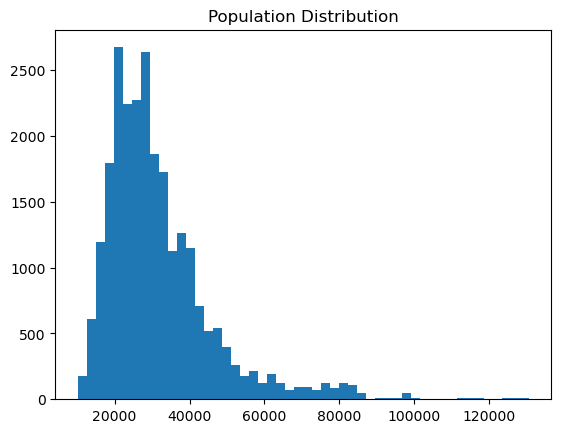

In [48]:
plt.hist(df['Population'], bins=50)
plt.title("Population Distribution")
plt.show()

# 1.calculating incidence rate

In [49]:
df["Incidence rate"]=(df["Respiratory Diseases"]/df["Population"]*100).round(1)

In [50]:
df

,District,Sector,year,Month,Respiratory Diseases,Air_Temperature,Average_temperature,Max_temperature,Min_ temperature,Precipitation (ERA5-Land),Relative humidity (ERA5-Land),Population,Incidence rate
0,Bugesera,Gashora,2020,Jan 2020,517,21.9,21.80,27.8,15.8,69.95,74.7,27623,1.9
1,Bugesera,Gashora,2020,Feb 2020,1575,22.0,22.25,28.3,16.2,94.72,75.9,27623,5.7
2,Bugesera,Gashora,2020,Mar 2020,902,21.6,22.20,28.3,16.1,162.71,78.9,27623,3.3
3,Bugesera,Gashora,2020,Apr 2020,565,21.2,22.15,28.0,16.3,206.08,80.1,27623,2.0
4,Bugesera,Gashora,2020,May 2020,543,21.4,20.90,27.2,14.6,48.58,71.3,27623,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
24955,Rwamagana,Rubona,2024,Aug 2024,321,23.8,24.00,31.0,17.0,7.59,44.0,31160,1.0
24956,Rwamagana,Rubona,2024,Sep 2024,329,23.4,24.35,31.6,17.1,55.59,53.6,31160,1.1
24957,Rwamagana,Rubona,2024,Oct 2024,329,21.9,23.10,29.8,16.4,148.26,67.6,31160,1.1
24958,Rwamagana,Rubona,2024,Nov 2024,365,21.0,21.75,27.8,15.7,226.29,75.3,31160,1.2


In [51]:
df2 = df[(df["Incidence rate"] >= 0) & (df["Incidence rate"] <= 100)]

In [52]:
df3=df2.groupby("year")["Incidence rate"].mean().round(2)

In [53]:
df3

year
2020    2.47
2021    2.92
2022    3.13
2023    2.77
2024    2.85
Name: Incidence rate, dtype: float64

In [54]:
df2.groupby(['District','year'])['Respiratory Diseases'].sum()

District   year
Bugesera   2020    112973
           2021    167156
           2022    140742
           2023    136847
           2024    162896
                    ...  
Rwamagana  2020    134268
           2021    164741
           2022    171238
           2023    163211
           2024    150008
Name: Respiratory Diseases, Length: 150, dtype: int64

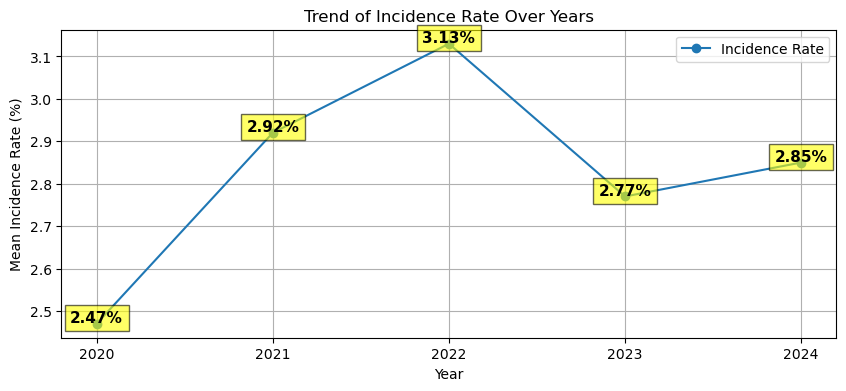

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# Data
years = np.array([2020, 2021, 2022, 2023, 2024])
incidence_rate = np.array([2.47, 2.92, 3.13, 2.77, 2.85])

# Fit a linear trendline
z = np.polyfit(years, incidence_rate, 1)
p = np.poly1d(z)

# Plot
plt.figure(figsize=(10,4))
plt.plot(years, incidence_rate, marker='o', linestyle='-', label='Incidence Rate')
# Highlight numbers
for x, y in zip(years, incidence_rate):
    plt.text(x, y + 0.003, f"{y:.2f}%",
             ha='center',
             fontsize=11,
             fontweight='bold',
             bbox=dict(facecolor='yellow', alpha=0.6, edgecolor='black'))

plt.xlabel("Year")
plt.ylabel("Mean Incidence Rate (%)")
plt.title("Trend of Incidence Rate Over Years")
plt.xticks(years)
plt.grid(True)
plt.legend()

In [56]:
from sklearn.utils import resample
df4 = resample(df, 
                    replace=True, 
                    n_samples=200000, 
                    random_state=42)

In [57]:
from sklearn.model_selection import train_test_split
# ==========================================
# 2. FEATURES AND TARGET
# ==========================================
X = df4[["Min_ temperature","Precipitation (ERA5-Land)","Relative humidity (ERA5-Land)","year"]]
y = df4["Respiratory Diseases"]

# ==========================================
# 3. NORMAL TRAIN-TEST SPLIT
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 1. Linear Regression

In [58]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
model_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

print("Linear Regression")
print("R2:", r2_score(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))

Linear Regression
R2: 0.018550539976923464
RMSE: 876.2159744118088


# 2. Ridge Regression

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
model_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=0.001))
])

model_ridge.fit(X_train, y_train)
y_pred_ridge = model_ridge.predict(X_test)

print("Ridge Regression")
print("R2:", r2_score(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))

Ridge Regression
R2: 0.018550539976335934
RMSE: 876.2159744120711


# 3. Lasso Regression

In [60]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
model_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01))
])

model_lasso.fit(X_train, y_train)
y_pred_lasso = model_lasso.predict(X_test)

print("Lasso Regression")
print("R2:", r2_score(y_test, y_pred_lasso))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))

Lasso Regression
R2: 0.01855062992387413
RMSE: 876.215934260502


# 4. Random Forest

In [61]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
model_rf = RandomForestRegressor(random_state=42)

model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

print("Random Forest")
print("R2:", r2_score(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))

Random Forest
R2: 0.817829655884902
RMSE: 377.49920011646554


# 5. Gradient Boosting

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
model_gb = GradientBoostingRegressor(random_state=42)

model_gb.fit(X_train, y_train)
y_pred_gb = model_gb.predict(X_test)

print("Gradient Boosting")
print("R2:", r2_score(y_test, y_pred_gb))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gb)))

Gradient Boosting
R2: 0.06045656552926559
RMSE: 857.305534511643


# 6. Support Vector Regression (SVR)

In [63]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import LinearSVR   # ✅ changed
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

model_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVR(max_iter=3000))  # ✅ faster
])

model_svr.fit(X_train, y_train)
y_pred_svr = model_svr.predict(X_test)

print("Linear SVR (Fast)")
print("R2:", r2_score(y_test, y_pred_svr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_svr)))

Linear SVR (Fast)
R2: -0.035223506710171826
RMSE: 899.9000145692336


# 7. K-Nearest Neighbors (KNN)

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
model_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])

model_knn.fit(X_train, y_train)
y_pred_knn = model_knn.predict(X_test)

print("KNN")
print("R2:", r2_score(y_test, y_pred_knn))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_knn)))

KNN
R2: 0.7466302749995407
RMSE: 445.1993857071233


# Step 1: Put all models in one dictionary

In [65]:
models = {
    "SVR": model_svr,
    "Gradient Boosting": model_gb,
    "KNN": model_knn,
    "Random Forest": model_rf,
    "Lasso": model_lasso,
    "Ridge": model_ridge,
    "Linear Regression": model_lr
}

# Step 2: Loop and evaluate

In [66]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    
    results.append({
        "Model": name,
        "R2": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred))
    })

# Step 3: Convert to table

In [67]:
results_df = pd.DataFrame(results)

# Sort by best performance
results_df = results_df.sort_values(by="R2", ascending=False)

print(results_df)

               Model        R2        RMSE
3      Random Forest  0.817830  377.499200
2                KNN  0.746630  445.199386
1  Gradient Boosting  0.060457  857.305535
4              Lasso  0.018551  876.215934
6  Linear Regression  0.018551  876.215974
5              Ridge  0.018551  876.215974
0                SVR -0.035224  899.900015


In [68]:
models

{'SVR': Pipeline(steps=[('scaler', StandardScaler()),
                 ('model', LinearSVR(max_iter=3000))]),
 'Gradient Boosting': GradientBoostingRegressor(random_state=42),
 'KNN': Pipeline(steps=[('scaler', StandardScaler()), ('model', KNeighborsRegressor())]),
 'Random Forest': RandomForestRegressor(random_state=42),
 'Lasso': Pipeline(steps=[('scaler', StandardScaler()), ('model', Lasso(alpha=0.01))]),
 'Ridge': Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge(alpha=0.001))]),
 'Linear Regression': Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())])}

# This saves your trained Random Forest model

In [69]:
import pickle               # dump(to save the model)

best_model_2026 = models["Random Forest"]

with open("C:/Users/user/Desktop/memoire/model.pkl", "wb") as f:
    pickle.dump(best_model_2026, f)

# 2. Load the Model

In [70]:
# Load model
with open("C:/Users/user/Desktop/memoire/model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

# 3. Make Predictions(using test Data)

In [71]:
y_pred = loaded_model.predict(X_test)
print(y_pred[:7])

[ 552.22  280.   1213.    488.2   278.   1132.   1526.  ]


# 4.make prediction (using New data)

In [72]:
# Example: [temperature, precipitation, humidity]
feature_names = ["Min_ temperature", "Precipitation (ERA5-Land)", "Relative humidity (ERA5-Land)", "year"]
new_data = pd.DataFrame([[400, 80, 123, 2029]], columns=feature_names)

prediction = loaded_model.predict(new_data)

print("Prediction:", prediction)

Prediction: [1322.34]


C:\Users\user\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
